# Любопытство: сколько стоит ещё один взгляд

> **English abstract.** A body that already knows *"is this the world, or is this
> something I made?"* still has to decide **which stream deserves another look**.
> This notebook builds that decision out of the same organism — no new model, no
> extra mathematics — as an expected information gain in four measured parts: how
> real the stream is (the mirror's own verdict), whether it moves at all, how much
> of its movement it explains *itself* against an exact null distribution, and how
> often it has already been asked. On the offline sensorium the ranking puts a
> **forgery** — a block of a real feed re-served — on top, at 0.815 against 0.000
> for three honest feeds, a control copy of the very same bytes and a frozen
> sensor. Thirty-three streams with no repeat in them fire nothing at all. The
> organism then spends six questions on the two forgeries — *where*, *what next*,
> *what is it really*, twice — and stops by arithmetic, not by a counter:
> 0.815 → 0.546 → 0.410 → 0.326.
>
> **Утверждение.** Любопытство — это не удивление и не дисперсия. Это цена
> внимания: произведение четырёх измеряемых множителей, каждый из которых можно
> распечатать и оспорить по отдельности.
>
> Правило, по которому этот ноутбук судится, объявлено **до** запуска:
>
> > если ранжирование ставит подделку выше всех честных потоков, детектор молчит
> > на тридцати перестановках настоящего ряда, а заданные вопросы кончаются сами —
> > правило пройдено; если хотя бы одно из трёх не выполняется, число не имеет
> > значения.
>
> Утверждение стоит чтения только из-за того, чем оно **не** является:
>
> * это не новая математика — ядро `entrain` не тронуто, признаки и `reality_score`
>   берутся у зеркала из предыдущего ноутбука;
> * это не подгонка под ответ: подделка ловится **своим повтором**, а не меткой —
>   в `Trait` нет поля «это подделка», и в потоке нет ни одного бита провенанса;
> * это не «детектор всего»: раздел «Чего эта проверка не видит» измеряет три
>   случая, на которых она молчит, и печатает числа, а не оговорку.

In [1]:
import json
import math
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agent.physics import curiosity as C
from agent.physics import sensorium as S
from agent.physics.organism import Organism

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 46)
np.set_printoptions(precision=3, suppress=True)
print("matplotlib", matplotlib.__version__, "| backend", matplotlib.get_backend())
print("curiosity:", {k: getattr(C, k) for k in
      ("SURVEY_FIXATIONS", "GAIN_SCALE", "PROBE_THRESHOLD", "ANOMALY_THRESHOLD",
       "MAX_PROBES", "LOOK_COST")})

matplotlib 3.11.2 | backend module://matplotlib_inline.backend_inline
curiosity: {'SURVEY_FIXATIONS': 24, 'GAIN_SCALE': 0.25, 'PROBE_THRESHOLD': 0.35, 'ANOMALY_THRESHOLD': 0.6, 'MAX_PROBES': 3, 'LOOK_COST': 0.5}


## 1. Тело, у которого уже есть зеркало

Организм берётся целиком из `agent.physics.organism`: откалиброванные
$\lambda$, $\varepsilon$, $\alpha$ и зеркало, которое отвечает на вопрос о
провенансе. Ничего не переобучается — любопытство использует **готовую** осанку
(`mirror.posture`) и **готовый** `reality_score`.

In [2]:
t0 = time.time()
body = Organism.hatch(offline=True, steps=120, seed=11)
print(f"{len(body.world)} потоков мира, {time.time() - t0:.1f} s")
for perception in body.world:
    print(f"  {perception.source:<34} {perception.values.size:5d} samples  "
          f"domain={perception.domain}")
mirror = body.mirror.summary()
print(f"\nприор P(world) = {mirror['prior']:.3f}  "
      f"| параметры: {json.dumps(mirror['parameters'])}")
print("леджер:", mirror["ledger"], "записей |",
      "пустой trace: тело ещё не жило, поэтому статистика reality появится "
      "в обследовании ниже")

3 потоков мира, 3.7 s
  recorded:digits                     4096 samples  domain=behavior
  recorded:diabetes                   4096 samples  domain=recorded
  recorded:wine                       2314 samples  domain=recorded

приор P(world) = 0.667  | параметры: {"lam": 0.99, "epsilon": 0.010000000000000009, "alpha": 0.05}
леджер: 0 записей | пустой trace: тело ещё не жило, поэтому статистика reality появится в обследовании ниже


## 2. Что лежит на столе

Тело видит три честных потока. Рядом с ними кладутся четыре кандидата — и ни
один из них не помечен:

| поток | как сделан | что должно быть видно |
|---|---|---|
| `forger:block256` | блок настоящего ряда длиной 256 отсчётов, повторённый | повтор каждые 4 фиксации |
| `forger:replay` | первая половина того же ряда, вставленная вместо второй | повтор со сдвигом 12 фиксаций |
| `control:copy` | те же отсчёты, **не** повторённые | ничего: это и есть мир |
| `dead:sensor` | датчик, отдающий своё среднее | ничего не движется |

Ни в одном `Perception` нет поля «это подделка»: `counterfeit` копирует значения и
провенанс, а `origin` у всех четырёх — `world`, потому что тело не может знать
иначе. Различать их будет только арифметика — и `control:copy` здесь для того,
чтобы было видно, что она различает не «мою метку», а повтор.

Окна берутся той же длины, что и в младенчестве (128 отсчётов, шаг 64): обследование
на другой длине окна измеряло бы признаки в кадре, к которому осанка не
подгонялась, — на этом легко получить «всё одинаково нереально», и это измерено,
а не предположено.

Одно число в таблице ниже заслуживает объяснения заранее: у `forger:replay`
$R^2 = 0.83$, а не $1.00$. Копия точная — одиннадцать пар окон из двенадцати
совпадают бит в бит, — но окно (128 отсчётов) шире шага (64), поэтому единственное
окно, накрывающее место вставки, смешивает обе половины и не может совпасть со
своей парой. Это цена измерения периода 768 отсчётов в кадре 128 отсчётов, и она
записана, а не замазана.

In [3]:
heard = max(body.world, key=lambda p: p.values.size)
# 24 fixations of 128 samples at a 64-sample hop need 23 hops plus one window.
n = C.SURVEY_FIXATIONS * 64 + 64
raw = np.asarray(heard.values, dtype=float)[:n]


def stream(label, data, origin=S.WORLD):
    return S.Perception(values=np.asarray(data, dtype=float), origin=origin,
                        source=label, domain=heard.domain, label=label)


forger = S.counterfeit(stream("forger:block256", raw), block=256,
                       source="forger:block256")
replay_values = raw.copy()
replay_values[768:1536] = raw[:768]
replay = stream("forger:replay", replay_values)
control = stream("control:copy", raw)
dead = stream("dead:sensor", np.full(n, raw.mean()))

body.explore(extra=[forger, replay, control, dead], ask=False)
ranked = body.curiosity.ranking()
survey_rows = body.curiosity.ranking()     # the survey, before any question is asked
columns = ["stream", "curiosity", "structure", "reducible", "lag", "reality",
           "movement", "fixations", "looks"]
pd.DataFrame(ranked)[columns].round(
    {"curiosity": 3, "structure": 2, "reducible": 2, "reality": 3, "movement": 3}
).set_index("stream")

,curiosity,structure,reducible,lag,reality,movement,fixations,looks
stream,,,,,,,,
forger:block256,0.815,20.72,1.00,4,0.815,0.300,24,0
forger:replay,0.807,1.78,0.83,12,0.852,0.237,24,0
control:copy,0.000,0.00,0.00,0,0.827,0.263,24,0
dead:sensor,0.000,0.00,0.00,0,0.000,0.000,24,0
recorded:diabetes,0.000,0.00,0.00,0,0.527,1.097,24,0
recorded:digits,0.000,0.00,0.00,0,0.827,0.263,24,0
recorded:wine,0.000,0.00,0.00,0,0.994,0.038,24,0


Колонки читаются ровно так, как записаны:

* `movement` — насколько поток вообще движется; у `dead:sensor` ровно ноль, и
  никакие другие числа его уже не спасут;
* `reducible` / `lag` — доля движения, которую поток объясняет **сам собой**, и
  через сколько фиксаций; `structure` — те же числа в натах, $-\ln(1-R^2)$;
* `reality` — вердикт зеркала: средний `reality_score` потока. У подделки он
  высокий не потому, что она подделана, а потому, что она правда состоит из
  настоящих отсчётов;
* `curiosity` — произведение, и оно единственное, что здесь упорядочено.

Чего в таблице **нет** — колонки «удивление». Она была бы самой большой у шума, и
именно поэтому шум не получает внимания.

In [4]:
for row in ranked:
    print(f"{row['stream']:<34} c={row['curiosity']:.3f}  "
          f"R²={row['reducible']:.2f}@{row['lag']:<2} Λ={row['structure']:5.2f}  "
          f"reality={row['reality']:.3f}  V={row['movement']:.3f}  "
          f"{row['note']}")

forger:block256                    c=0.815  R²=1.00@4  Λ=20.72  reality=0.815  V=0.300  repeats every 4 fixations (256 samples)
forger:replay                      c=0.807  R²=0.83@12 Λ= 1.78  reality=0.852  V=0.237  repeats every 12 fixations (768 samples)
control:copy                       c=0.000  R²=0.00@0  Λ= 0.00  reality=0.827  V=0.263  
dead:sensor                        c=0.000  R²=0.00@0  Λ= 0.00  reality=0.000  V=0.000  
recorded:diabetes                  c=0.000  R²=0.00@0  Λ= 0.00  reality=0.527  V=1.097  
recorded:digits                    c=0.000  R²=0.00@0  Λ= 0.00  reality=0.827  V=0.263  
recorded:wine                      c=0.000  R²=0.00@0  Λ= 0.00  reality=0.994  V=0.038  


## 3. Четыре множителя по отдельности

$$c = R \cdot \min\left(1, \frac{2V}{V + V_{\text{ref}}}\right) \cdot
      \left(1 - e^{-\Lambda/0.25}\right) \cdot \frac{1}{1 + 0.5\,\text{looks}}$$

`score` вынесена из класса, чтобы каждый множитель можно было провести по всей оси
и увидеть, какой формы он на самом деле. Рядом печатается гейн Линдли
$\Delta H = \tfrac12\ln(1+\tau^2/\sigma^2)$ — честная величина, которая **не
зависит от потока** и потому не может быть правилом выбора: у двух потоков, к
которым тело присматривалось одинаково часто, она одна и та же.

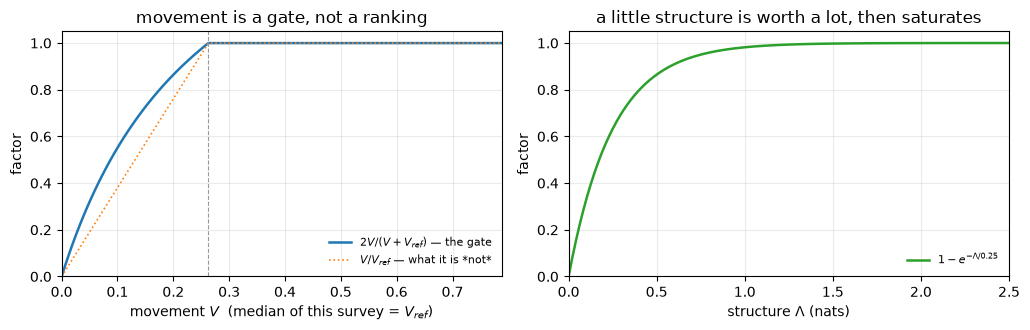

looks → curiosity: 0: 0.982  1: 0.654  2: 0.491  3: 0.393  4: 0.327  5: 0.280
Lindley, τ=σ=1, same looks: 0: 0.347  1: 0.203  2: 0.144  3: 0.112  4: 0.091  5: 0.077  ← one number for every stream: it cannot rank


In [5]:
reference = float(np.median([t["movement"] for t in ranked]))
moves = np.linspace(0.0, 3.0 * reference, 121)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.4))
axes[0].plot(moves, [C.score(v, reference, 2.0, 1.0) for v in moves], lw=1.8,
             label="$2V/(V+V_{ref})$ — the gate")
axes[0].plot(moves, [min(1.0, v / max(reference, 1e-9)) for v in moves], ls=":",
             lw=1.2, label="$V/V_{ref}$ — what it is *not*")
axes[0].axvline(reference, color="0.6", lw=0.8, ls="--")
axes[0].set_xlabel("movement $V$  (median of this survey = $V_{ref}$)")
axes[0].set_ylabel("factor")
axes[0].set_xlim(0, moves[-1])
axes[0].set_ylim(0, 1.05)
axes[0].set_title("movement is a gate, not a ranking")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")

nats = np.linspace(0.0, 2.5, 121)
axes[1].plot(nats, [C.score(1.0, 1.0, lam, 1.0) for lam in nats], lw=1.8,
             color="C2", label="$1-e^{-\\Lambda/0.25}$")
axes[1].set_xlabel("structure $\\Lambda$ (nats)")
axes[1].set_ylabel("factor")
axes[1].set_xlim(0, nats[-1])
axes[1].set_ylim(0, 1.05)
axes[1].set_title("a little structure is worth a lot, then saturates")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
plt.show()

print("looks → curiosity:",
      "  ".join(f"{k}: {C.score(1.0, 1.0, 1.0, 1.0, k):.3f}" for k in range(6)))
print("Lindley, τ=σ=1, same looks:",
      "  ".join(f"{k}: {C.lindley_gain(1.0, 1.0, k):.3f}" for k in range(6)),
      " ← one number for every stream: it cannot rank")

## 4. Почему $R^2$ судится против распределения, а не против порога

Максимум по $21$ лагу — не маленькое число: на двадцати четырёх окнах белый шум
даёт $R^2$ от 0.28 до 0.91, медиана 0.56 (двести прогонов). Тело, которое верит
порогу 0.5, находит структуру в каждом втором шумовом потоке. Порог здесь не
спасает в принципе: высокие $R^2$ приходят с **коротких** лагов, где остаётся три
пары окон и любая прямая проходит близко. Поэтому лаг считается найденным, только
если $P(R^2 > r) = (1-r)^{(n-2)/2}$ меньше $\alpha/\text{(число лагов)}$: это
точное распределение для одной регрессии, а Бонферрони по лагам делает из него
семейную ошибку. В показателе стоит число **пар**, а не окон: у короткого лага пар
мало, и он судится строже.

Проверка — не рассуждение, а измерение: сколько раз **вся процедура** срабатывает
на чистом шуме, если ослабить $\alpha$. Объявленная частота — это граница, которую
гейт не имеет права превысить; измеренная обязана быть не больше неё.

In [6]:
dims = len(S.FEATURES)
rng = np.random.default_rng(20)
trials = 120
print(f"pure noise, {C.SURVEY_FIXATIONS} windows × {dims} features, {trials} trials")
for alpha in (0.5, 0.2, 0.1, 0.05, C.PROBE_ALPHA):
    fired = sum(
        1 for _ in range(trials)
        if C.reducibility(rng.normal(size=(C.SURVEY_FIXATIONS, dims)), alpha=alpha)[1] > 0
    )
    print(f"  alpha={alpha:<8} declared {alpha:6.1%}   measured {fired / trials:6.1%}"
          f"   ({fired} of {trials})")

pure noise, 24 windows × 7 features, 120 trials


  alpha=0.5      declared  50.0%   measured   0.0%   (0 of 120)


  alpha=0.2      declared  20.0%   measured   0.0%   (0 of 120)


  alpha=0.1      declared  10.0%   measured   0.0%   (0 of 120)


  alpha=0.05     declared   5.0%   measured   0.0%   (0 of 120)


  alpha=0.01     declared   1.0%   measured   0.0%   (0 of 120)


Строки надо читать как одно число: **ноль**. Даже при $\alpha = 0.5$, где объявлена
половина, гейт не срабатывает ни на одном из ста двадцати шумовых потоков. Причина
арифметическая, а не осторожная настройка: на лаге 21 из двадцати четырёх окон
остаётся три пары, и чтобы хвост $(1-R^2)^{(3-2)/2}$ упал ниже $0.5/21$, нужно
$R^2 \ge 0.9994$. Объявленный $\alpha$ — граница, которую гейт не выбирает, а
обходит с большим запасом: он ошибается только в сторону молчания. Цена этой
осторожности — чувствительность, и она измерена в §8.

## 5. Батарея потоков без повтора

Тридцать перестановок настоящего ряда (шум внутри собственного распределения
потока — самая опасная подделка для любой статистики), случайное блуждание,
AR(1) на разрешении обследования и замороженный датчик. Ни в одном из них повтора
нет, и ни один не должен получить структуру.

In [7]:
engine = C.Curiosity(body.mirror.posture, prior=body.mirror.prior)
walk = np.cumsum(rng.normal(size=n)) * 0.05 + raw.mean()
ar1 = np.zeros(n)
for i in range(1, n):
    ar1[i] = 0.9 * ar1[i - 1] + rng.normal() * 0.3
battery = ([stream(f"shuffle:{k:02d}", rng.permutation(raw)) for k in range(30)]
           + [stream("walk", walk), stream("ar1", ar1 + raw.mean()),
              stream("frozen", np.full(n, raw.mean()))])
episodes = [body.sensorium.fixate(p, limit=C.SURVEY_FIXATIONS) for p in battery]
quiet = engine.survey(episodes)

fired = [t for t in quiet if t.lag > 0]
print(f"{len(quiet)} потоков без повтора, сработало {len(fired)}")
print(f"  max R² = {max(t.reducible for t in quiet):.3f}, "
      f"max structure = {max(t.structure for t in quiet):.2f} nats, "
      f"max curiosity = {max(t.curiosity for t in quiet):.3f}")
by_kind: dict = {}
for trait in quiet:
    kind = trait.stream.split(":")[0]
    by_kind.setdefault(kind, []).append(trait)
for kind, group in sorted(by_kind.items()):
    print(f"  {kind:<9} n={len(group):2d}  fired={sum(t.lag > 0 for t in group)}  "
          f"max reality={max(t.reality for t in group):.3f}  "
          f"max V={max(t.movement for t in group):.3f}")

33 потоков без повтора, сработало 0
  max R² = 0.000, max structure = 0.00 nats, max curiosity = 0.000
  ar1       n= 1  fired=0  max reality=0.022  max V=1.148
  frozen    n= 1  fired=0  max reality=0.000  max V=0.000
  shuffle   n=30  fired=0  max reality=0.851  max V=0.978
  walk      n= 1  fired=0  max reality=0.013  max V=2.160


Замороженный поток здесь — единственный, у кого `movement` равен нулю, и он же
единственный, кого не спасает даже высокий `reality`: гейт движения стоит в
числителе произведения, а не в сумме.

## 6. Диалог: три вопроса и тишина после них

Тело не ждёт данных — оно **просит** их. Каждый вопрос стоит доли любопытства
(:data:`LOOK_COST`), поэтому второй вопрос про тот же поток стоит две трети
первого, а третий — половину, и цикл заканчивается арифметически, а не по счётчику.

Защёлок две, и они не равны по силе. **Скоба** — порог :data:`PROBE_THRESHOLD`:
пока любопытство выше порога, вопрос есть. **Ремень** — :data:`MAX_PROBES` = 3
вопроса на поток. Здесь ремень отодвигается до 12 намеренно: со штатным потолком
он закрыл бы поток раньше порога, и было бы не видно, что именно его остановило.
Если тело остановится раньше двенадцати — остановила его арифметика.

Видов вопроса три, и они же — три доступных телу способа посмотреть:

* `context` — покажи, что было вокруг самого неожиданного места;
* `next` — покажи следующий пакет того же потока;
* `compare` — покажи этот поток рядом с тем, который мне наименее интересен.

In [8]:
before = {row["stream"]: row["curiosity"] for row in body.curiosity.ranking()}
body.curiosity.max_probes = 12        # снять ремень: пусть решает порог
asked = body.ask(answers=12)
print(f"{len(asked)} вопросов\n")
for entry in body.probe_log:
    print(f"  шаг {entry['step']}: {entry['kind']:<8} {entry['stream']:<18} "
          f"{entry['question'][:50]:<50} c {entry['curiosity']:.3f} → "
          f"{entry['after']:.3f}  ({entry['samples']} отсчётов, "
          f"ответ {entry['answered']})")

after = body.curiosity.ranking()
print("\nчто изменилось в ранге:")
for row in after:
    old = before.get(row["stream"], 0.0)
    if abs(row["curiosity"] - old) > 1e-9 or row["looks"]:
        print(f"  {row['stream']:<24} {old:.3f} → {row['curiosity']:.3f}  "
              f"(looks={row['looks']}, fixations={row['fixations']})")
print("\nвопросов больше не задаётся:", body.curiosity.propose() is None)
for trait in body.curiosity.traits()[:2]:
    closed_by = ("порог" if trait.curiosity < body.curiosity.threshold
                 else "ремень")
    print(f"  {trait.stream:<18} c={trait.curiosity:.3f} < "
          f"{body.curiosity.threshold}  looks={trait.looks}/"
          f"{body.curiosity.max_probes}  → закрыл: {closed_by}")
print("потоков, о которых ещё стоит спрашивать:",
      [t.stream for t in body.curiosity.curious()] or "ни одного")

6 вопросов

  шаг 1: context  forger:block256    forger:block256: what happened 96 samples either s c 0.815 → 0.546  (192 отсчётов, ответ True)
  шаг 2: context  forger:replay      forger:replay: what happened 96 samples either sid c 0.807 → 0.540  (192 отсчётов, ответ True)
  шаг 3: next     forger:block256    forger:block256: what comes next, after sample 192 c 0.546 → 0.410  (192 отсчётов, ответ True)
  шаг 4: next     forger:replay      forger:replay: what comes next, after sample 192?  c 0.540 → 0.407  (192 отсчётов, ответ True)
  шаг 5: compare  forger:block256    forger:block256: is this forger:block256 at all, n c 0.410 → 0.326  (192 отсчётов, ответ True)
  шаг 6: compare  forger:replay      forger:replay: is this forger:replay at all, next  c 0.407 → 0.325  (192 отсчётов, ответ True)

что изменилось в ранге:
  forger:block256          0.815 → 0.326  (looks=3, fixations=24)
  forger:replay            0.807 → 0.325  (looks=3, fixations=24)

вопросов больше не задаётся: True
  fo

Обратите внимание на `fixations`: ответ на вопрос **не** добавляет строк в
обследование. Вопрос — это срез, улика об одном месте потока, а не новый поток:
если бы ответ дописывался в матрицу окон, заданный вопрос менял бы ту самую
структуру, из-за которой он был задан.

## 7. Рисунок: тот же аргумент, нарисованный

Четыре панели: рейтинг с порогом, где тело перестаёт смотреть; структура против
реальности (подделка — справа сверху, замороженный датчик — в левом нижнем углу);
гейн Линдли против любопытства (он ставит наверх самый громкий поток, а не
подделку); и диалог до/после.

Панели 1–3 берут рейтинг **на момент обследования**, а не после разговора: иначе на
картинке была бы уже уставшая очередь, и первая панель рассказывала бы не о том, что
тело нашло, а о том, что от него осталось.

curious_agent.png


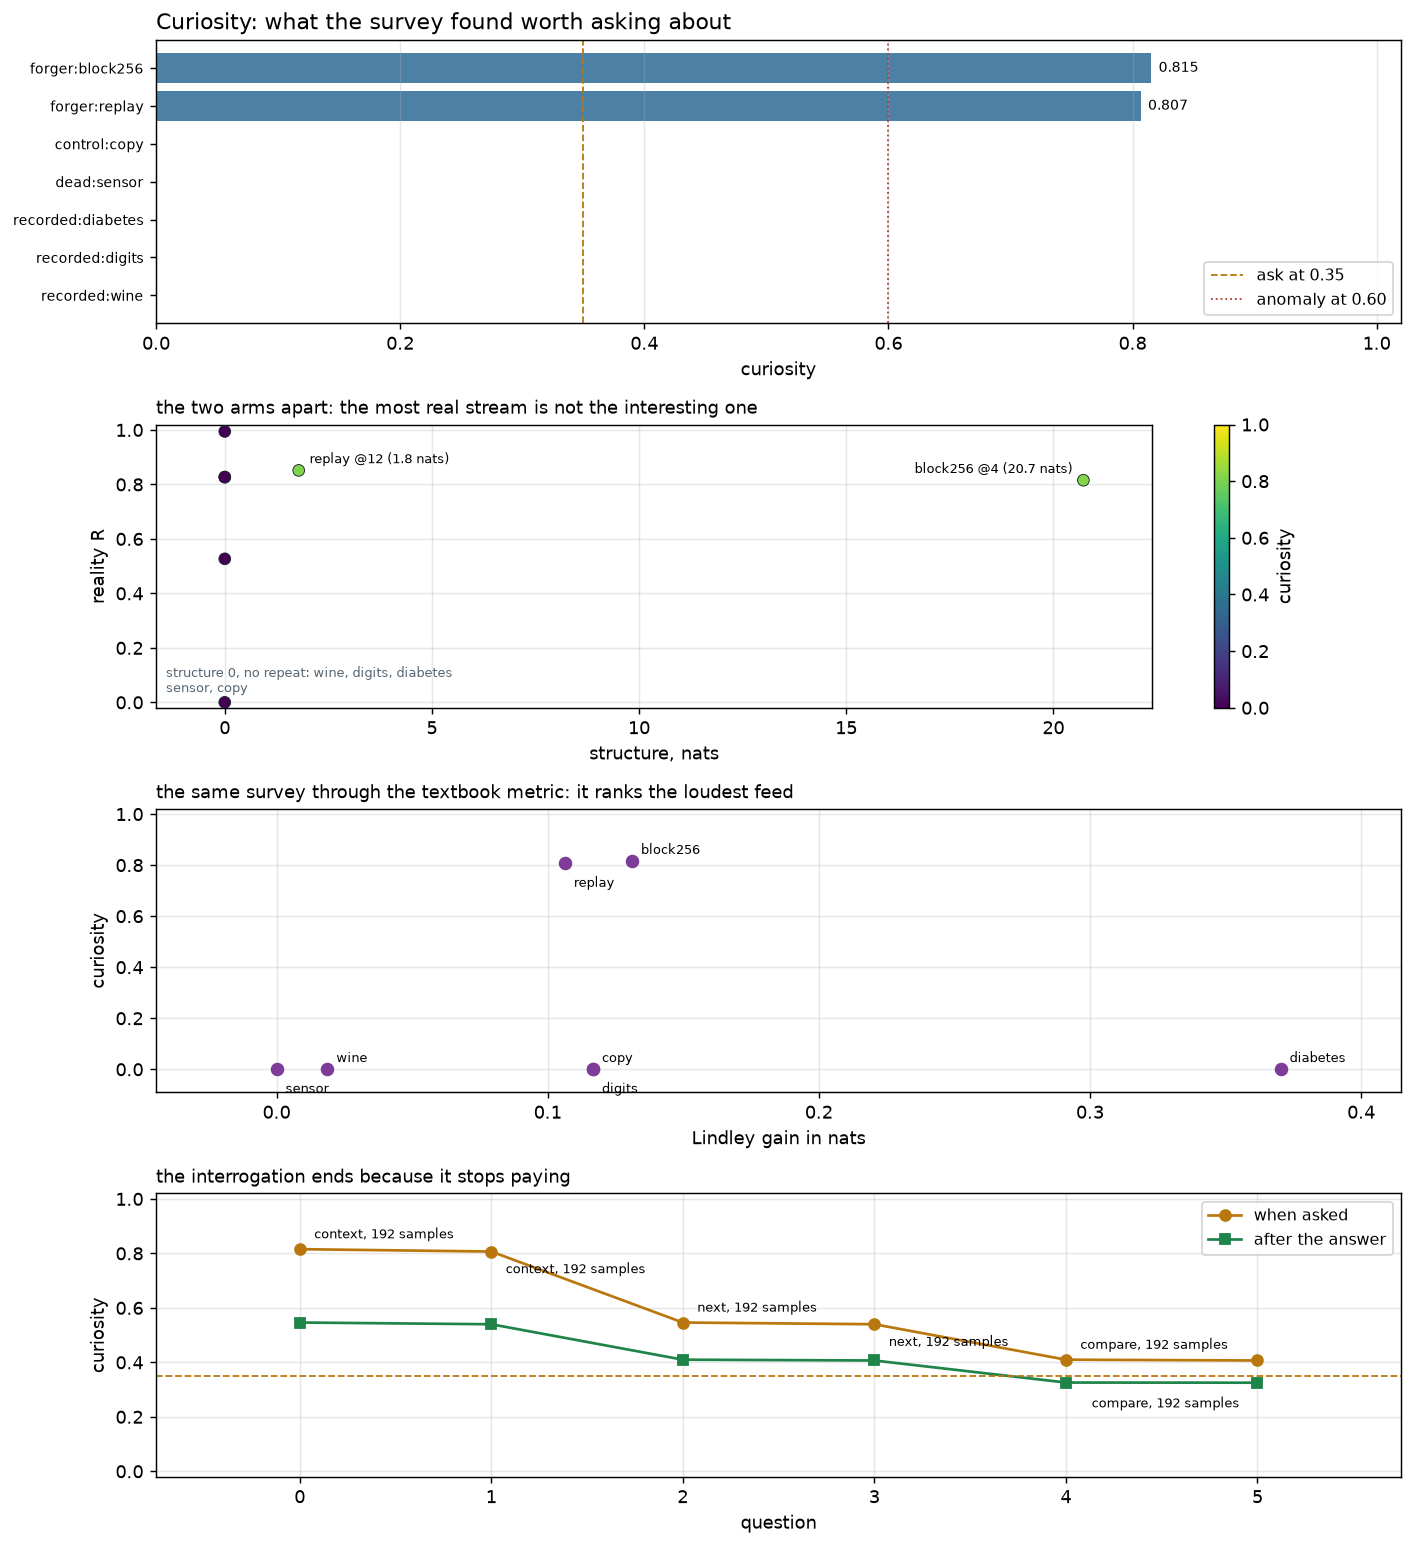

In [9]:
from IPython.display import Image, display

from agent.physics.plots import plot_curiosity

figure = plot_curiosity(survey_rows, "curious_agent.png", probes=body.probe_log,
                        threshold=body.curiosity.threshold)
print(figure)
display(Image(filename=str(figure), width=1080))

## 8. Чего эта проверка не видит

Структура считается по признакам **целого окна**, поэтому ловится переслуженный
payload, а не периодичность сводки. Ниже — три потока, на которых это видно, все
измеренные, а не заявленные:

* чистый синус с периодом 512 отсчётов: повтор находится (признаки инвариантны к
  смене знака, поэтому возвращается полпериода — честный ответ **в этом кадре**),
  но `reality` = 0.00: зеркало никогда не слышало сигнала без шума и говорит об
  этом. Структура без реальности не стоит ничего;
* тот же синус с $\sigma = 0.3$ шума не считается повтором вовсе: сводки окна
  синуса меняются меньше, чем шум, — и после того как фаза потеряна, искать
  самоподобие не в чем;
* подделка блоком в 128 отсчётов — ровно одно окно: структура её видит
  ($R^2 = 1.00$ на лаге 1: два чередующихся окна предсказывают друг друга
  наклоном $-1$, и полоса равных лагов возвращает меньший), `reality` высокая, но
  `movement` в кадре почти нулевой — окна такой подделки почти не отличаются друг
  от друга, — и гейт движения обнуляет произведение.

In [10]:
rhythm_engine = C.Curiosity(body.mirror.posture, prior=body.mirror.prior)
sine = np.sin(2 * np.pi * np.arange(n) / 512.0)
short = S.counterfeit(stream("forger:block128", raw), block=128,
                      source="forger:block128")
edge = [stream("rhythm:clean", sine),
        stream("rhythm:noisy", sine + 0.3 * rng.normal(size=n)), short]
for trait in rhythm_engine.survey(
        [body.sensorium.fixate(p, limit=C.SURVEY_FIXATIONS) for p in edge]):
    print(f"{trait.stream:<16} R²={trait.reducible:.3f}@{trait.lag:<3} "
          f"Λ={trait.structure:5.2f}  reality={trait.reality:.3f}  "
          f"V={trait.movement:.4f}  c={trait.curiosity:.3f}  {trait.note}")
print(f"\nпорог вопроса: {C.PROBE_THRESHOLD} — ни один из трёх его не берёт")

forger:block128  R²=1.000@1   Λ=20.72  reality=0.863  V=0.0035  c=0.007  repeats every 1 fixations (64 samples); reality without the ledger
rhythm:clean     R²=0.999@4   Λ= 6.85  reality=0.000  V=3.9223  c=0.000  repeats every 4 fixations (256 samples); reality without the ledger
rhythm:noisy     R²=0.000@0   Λ= 0.00  reality=0.501  V=0.8333  c=0.000  reality without the ledger

порог вопроса: 0.35 — ни один из трёх его не берёт


Сказать это прямо важнее, чем спрятать: детектор отвечает на вопрос «это то же
самое окно ещё раз», то есть ровно на тот вопрос, который задаёт подделка, — и не
отвечает ни на вопрос «это мелодия», ни на вопрос «это подделка короче окна».

## 9. Правило

Объявлено в начале, проверяется в конце — как булевы значения, а не как текст:

1. подделка получает больше внимания, чем любой честный поток;
2. контрольная копия тех же отсчётов без повтора не получает внимания вообще;
3. замороженный датчик не получает внимания вообще;
4. ни один поток без повтора не срабатывает;
5. вопросы кончаются сами, и любопытство к спрошенному падает монотонно.

In [11]:
top = after[0]["stream"]
honest = {p.source for p in body.world}
drops = [entry["curiosity"] - entry["after"] for entry in body.probe_log]
forged = max(row["curiosity"] for row in after
             if row["stream"].startswith("forger"))
honest_top = max((row["curiosity"] for row in after
                  if row["stream"] in honest | {"control:copy"}), default=0.0)


def curiosity_of(name):
    return next(row["curiosity"] for row in after if row["stream"] == name)


rules = {
    "подделка наверху": top.startswith("forger"),
    "подделка выше честных": forged > honest_top,
    "копия без повтора молчит": curiosity_of("control:copy") == 0.0,
    "мёртвый датчик молчит": curiosity_of("dead:sensor") == 0.0,
    "потоки без повтора молчат": len(fired) == 0,
    "вопросы кончились сами": body.curiosity.propose() is None,
    "любопытство падает": all(d > 0 for d in drops),
}
for name, passed in rules.items():
    print(f"  {'ok  ' if passed else 'FAIL'}  {name}")
print("\nвсё правило пройдено:", all(rules.values()))
print("задано вопросов:", len(body.probe_log),
      "| падение любопытства:", " → ".join(f"{d:.3f}" for d in drops))

  ok    подделка наверху
  ok    подделка выше честных
  ok    копия без повтора молчит
  ok    мёртвый датчик молчит
  ok    потоки без повтора молчат
  ok    вопросы кончились сами
  ok    любопытство падает

всё правило пройдено: True
задано вопросов: 6 | падение любопытства: 0.269 → 0.267 → 0.136 → 0.133 → 0.084 → 0.081


Последнее, что стоит унести: любопытство здесь — не свойство потока, а **цена**
следующего взгляда на него. Она падает, как только взгляд сделан, и это
единственное, что заставляет тело перестать смотреть, — не терпение, а
арифметика.